# 현실의 데이터 33: 체스: 누가 이길까?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/33_chess.ipynb)

**분야**: 스포츠 · 게임 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 게임 데이터 · 승패 예측 · 실력 측정 (레이팅)

> 두 사람의 레이팅만 보고 누가 이길지 알 수 있을까?

**데이터**: Lichess 공개 대국 · 2013년 1월 (약 37MB). 온라인 체스 Lichess 의 모든 대국 기록 (CC0) 중 2013년 1월 121,332판 (Hugging Face Lichess/standard-chess-games): 결과 · 두 사람 레이팅 · 시간 규칙 · 수 기록.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 대국 하나 |
| ② 입력 X | 백 · 흑 레이팅, 레이팅 차, 시간 규칙 |
| ③ 출력 y | 백 승 / 무승부 / 흑 승 |
| ④ 평가지표 | 정확도 · 로그 손실 |
| ⑤ 기준선 | 레이팅이 높은 쪽이 이긴다 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [McIlroy-Young et al. (2020) Aligning Superhuman AI with Human Behavior: Chess as a Model System (Maia), KDD](https://arxiv.org/abs/2006.01855)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
URL = "https://huggingface.co/datasets/Lichess/standard-chess-games/resolve/main/data/year=2013/month=01/train-00000-of-00001.parquet"
df = pd.read_parquet(download(URL, "data/lichess_2013_01.parquet"), columns=["Result", "WhiteElo", "BlackElo", "TimeControl", "Termination", "Opening", "movetext"])
print(df.shape)
print(df["Result"].value_counts().to_dict())
df.drop(columns="movetext").sample(5, random_state=0)

(121332, 7)
{'1-0': 62129, '0-1': 55221, '1/2-1/2': 3982}


,Result,WhiteElo,BlackElo,TimeControl,Termination,Opening
42611,1-0,1459.0,1500.0,300+0,Time forfeit,Queen's Gambit Declined
54179,0-1,1768.0,1190.0,420+8,Time forfeit,Horwitz Defense
16864,1-0,1540.0,1380.0,420+4,Normal,Queen's Gambit Refused: Marshall Defense
61638,1-0,1494.0,1621.0,420+3,Normal,Sicilian Defense: Loewenthal Variation
32000,1-0,1583.0,1026.0,60+0,Time forfeit,Bishop's Opening


## 열어 보기

레이팅 차 (백 − 흑) 에 따라 백이 이긴 비율은? 레이팅 (Elo) 은 원래 '차이가 400 이면 높은 쪽이 약 91% 이긴다' 가 되도록 만든 숫자다.

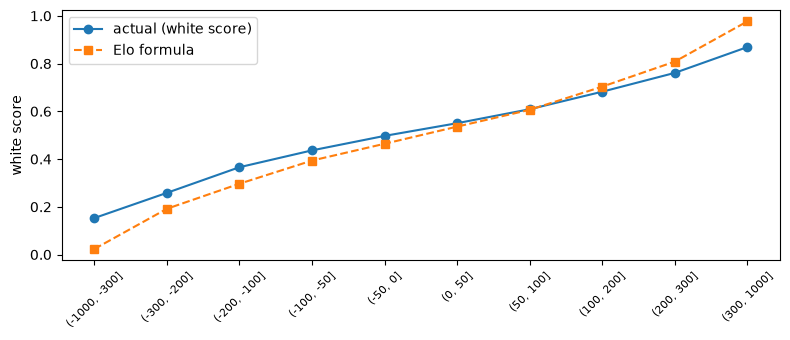

In [3]:
df = df[df["Result"].isin(["1-0", "0-1", "1/2-1/2"])].copy()
df["WhiteElo"] = pd.to_numeric(df["WhiteElo"], errors="coerce"); df["BlackElo"] = pd.to_numeric(df["BlackElo"], errors="coerce")
df["diff"] = df["WhiteElo"] - df["BlackElo"]
df["base_sec"] = pd.to_numeric(df["TimeControl"].str.split("+").str[0], errors="coerce")
bins = pd.cut(df["diff"], [-1000, -300, -200, -100, -50, 0, 50, 100, 200, 300, 1000])
win = df.groupby(bins, observed=True)["Result"].apply(lambda r: (r == "1-0").mean() + 0.5 * (r == "1/2-1/2").mean())
elo = 1 / (1 + 10 ** (-np.array([(-650), -250, -150, -75, -25, 25, 75, 150, 250, 650]) / 400))
plt.figure(figsize=(8, 3.5)); plt.plot(range(len(win)), win.values, "o-", label="actual (white score)"); plt.plot(range(len(win)), elo, "s--", label="Elo formula")
plt.xticks(range(len(win)), [str(i) for i in win.index], rotation=45, fontsize=8); plt.ylabel("white score"); plt.legend(); plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 대국 → 결과 (3가지)

**날짜 순서** (데이터가 시간 순서로 놓여 있다) 로 앞 80% 학습, 뒤 20% 시험.
- 기준선 1: 늘 '백 승' (백이 먼저 두니까)
- 기준선 2: 레이팅이 높은 쪽이 이긴다
- 모델: 레이팅 · 차 · 시간 규칙으로 로지스틱회귀 (확률까지)

In [4]:
from sklearn.linear_model import LogisticRegression

d = df.dropna(subset=["base_sec", "diff", "WhiteElo", "BlackElo"])
X = np.c_[d["diff"], (d["WhiteElo"] + d["BlackElo"]) / 2, np.log1p(d["base_sec"])]
y = d["Result"].map({"1-0": 0, "1/2-1/2": 1, "0-1": 2}).values
cut = int(len(d) * 0.8); tr, te = slice(0, cut), slice(cut, None)
m = LogisticRegression(max_iter=2000).fit(X[tr] / [100, 1000, 1], y[tr])
prob = m.predict_proba(X[te] / [100, 1000, 1])
higher = np.where(X[te][:, 0] >= 0, 0, 2)
print(f"always white wins     : accuracy {np.mean(y[te] == 0):.1%}")
print(f"higher rating wins    : accuracy {np.mean(y[te] == higher):.1%}")
print(f"logistic (3 numbers)  : accuracy {np.mean(y[te] == prob.argmax(1)):.1%}, "
      f"log loss {-np.mean(np.log(prob[np.arange(len(prob)), y[te]] + 1e-9)):.3f}")
print(f"draw rate in test: {np.mean(y[te] == 1):.1%}")

always white wins     : accuracy 51.3%
higher rating wins    : accuracy 64.2%
logistic (3 numbers)  : accuracy 64.1%, log loss 0.730
draw rate in test: 3.2%


**관찰**: 레이팅 차만으로도 동전 던지기보다 훨씬 잘 맞힌다. 무승부는 드물어서 거의 맞히지 못한다. 그런데 `movetext` (둔 수 전체) 나 `Termination` (어떻게 끝났나) 을 입력에 넣으면? **경기가 끝나야 알 수 있는 값** 이라 누수다.

## 다른 문제로 바꿔 보기

- **수 예측**: 한 행 = 한 수, 입력 = 지금 판, 출력 = 사람이 둘 다음 수. 레이팅마다 다르게 두는 '사람 같은 AI' (Maia, 아래 논문).
- **부정행위 탐지**: 사람의 레이팅에 비해 너무 엔진 같은 수만 두는 계정 찾기.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |